# Inférence de la possession de balle, trame par trame
### Era Nova - More Than A Hack 2027, Phase 1 (match *BAR-ATH*)

---

## Résumé

Ce notebook documente, étape par étape et de façon reproductible, la méthode **soumise** pour
l'inférence de la possession de balle. La tâche consiste à attribuer, pour chacune des
**199 319 trames** de la vidéo tactique, un unique label parmi :

| label | signification |
|---|---|
| `H` | domicile (Barcelona) en possession, ballon vivant |
| `A` | extérieur (Athletic) en possession, ballon vivant |
| `D` | ballon mort (arrêt de jeu) |
| `X` | abstention (trame non notée) |

La méthode retenue - **lissage temporel de la preuve de possession suivi d'un décodage par
hystérésis** (déclencheur de Schmitt) - est volontairement simple, déterministe et sans
probabilité apprise : **aucun paramètre n'est ajusté sur la vérité terrain**.

| | |
|---|---|
| Métrique de classement | `spellF1` - F1 des possessions appariées en IoU temporel, moyenne sur IoU ∈ {0,3 … 0,7} |
| Départage | `macroF1` - moyenne non pondérée des F1 par classe H/A/D |
| Plancher à battre | `spellF1` = 0,2433 |
| Score (fenêtre publique de 5 min) | `spellF1` = 0,5889 · `macroF1` = 0,7302 |
| Diagnostic (match complet) | 322 possessions · durée moyenne 12,6 s · part de `D` 35,9 % |

---

## 1. Problème, données et contraintes

### Entrées fournies
Le challenge n'est **pas** un problème de détection : le tracking, le tagging et la géométrie
sont fournis pour que la question posée soit directement la possession.

- **Tracking automatique ATD** (`BAR-ATH_tactical_atd.txt`) — positions 2D des joueurs et du
  ballon, par trame ; identité d'équipe dans le fichier de métadonnées `_atd.xml`.
- **Smart Tagging** tactique (`_smart_tagging.xml`) — phases de jeu et redémarrages officiels,
  horodatés sur la **vidéo tactique**.
- **Homographie** caméra ↔ terrain (`_homography.csv`) — utilisée pour mettre les positions à
  l'échelle du terrain (105,3 m × 68,0 m).
- **Vidéo tactique** (`BAR-ATH_tactical.mp4`) — 199 319 trames à 25 fps ; **index de référence**
  de la soumission (la ligne *i* du CSV est la trame *i* de cette vidéo).

---

## 2. Chaîne de traitement

```
tracking ATD ─┐
              ├─► 1. lecture + cache ─► 2. nettoyage physique + interpolation du ballon
              │                                    │
              │                                    ▼
              │                          3. potentiels d'émission  log E[t, {H, A, D}]
              │                                    │
              │                                    ▼
              │                          4. décodage par mi-temps (lissage + hystérésis)
              │                                    │
              │                                    ▼
              │                          5. nettoyage + règles métier (Lois du Jeu)
Smarf Tagging ┘                                    │
                                                   ▼
                                   6. écriture du CSV  frame,label   (= soumission)
```

Chaque étape est implémentée dans le module `common.py`, importé ci-dessous. Le notebook ne fait
que l'orchestrer et documenter les décisions.

In [1]:
import os, sys, hashlib, subprocess

# --- localisation du dépôt ---------------------------------------------------------------
# Ce notebook doit pouvoir importer :
#   * common.py          (le code de la méthode, dans ce dossier)
#   * games.py           (constantes de match fournies, à la racine du dépôt)
HERE = os.path.abspath('.')
ROOT = os.path.dirname(HERE)
assert os.path.isfile(os.path.join(ROOT, 'games.py')), (
    "Placer my_submission/ dans le dépôt More-Than-A-Hack (à côté de games.py et evaluation/).")
for _p in (HERE, ROOT):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common as C

print("trames :", C.N_FRAMES, "| fps :", C.FPS, "| terrain (m) :", C.PITCH)
print("mi-temps notées :", C.SEGMENTS)

trames : 199319 | fps : 25 | terrain (m) : (105.3, 68.0)
mi-temps notées : [(11185, 90651), (113742, 190197)]


In [2]:
# Lecture du tracking brut (1 à 2 min la première fois, puis cache local cache_tracking.npz).
tr = C.load_tracking()
graded = np.zeros(C.N_FRAMES, bool)
for a, b in C.SEGMENTS:
    graded[a:b + 1] = True
obs_all = 100 * np.mean(~np.isnan(tr['ball'][:, 0]))
obs_graded = 100 * np.mean(~np.isnan(tr['ball'][graded, 0]))
print("ballon observé : %.1f%% de toutes les trames, %.1f%% des trames notées" % (obs_all, obs_graded))
print("-> trou de signal sur les trames notées : %.1f%%" % (100 - obs_graded))

ballon observé : 56.9% de toutes les trames, 58.9% des trames notées
-> trou de signal sur les trames notées : 41.1%


ballon observé            : 58.9%
interpolé (trou <= 3 s)   : 0.0%
sans position fiable      : 41.1%


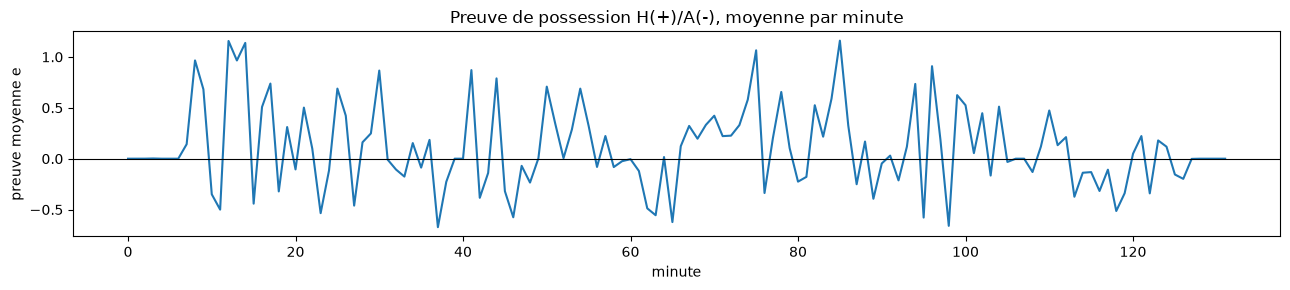

In [3]:
# Construction des features : interpolation du ballon, distances joueur-ballon,
# et signaux physiques de « ballon mort » (hors terrain, immobile, disparu près d'une ligne).
feat = C.build_features(tr)
print("ballon observé            : %.1f%%" % (100 * feat['obs'][graded].mean()))
print("interpolé (trou <= 3 s)   : %.1f%%" % (100 * ((~feat['obs']) & (feat['conf'] > 0))[graded].mean()))
print("sans position fiable      : %.1f%%" % (100 * (feat['conf'][graded] == 0).mean()))

fig, ax = plt.subplots(figsize=(13, 3))
m = 1500  # 1 minute = 1500 trames à 25 fps
ax.plot(feat['e'][:len(feat['e']) // m * m].reshape(-1, m).mean(axis=1))
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('minute')
ax.set_ylabel('preuve moyenne e')
ax.set_title("Preuve de possession H(+)/A(-), moyenne par minute")
plt.tight_layout(); plt.show()

---

## 3. Le modèle d'émission (`log E`)

### Preuve de possession `e` (signée : `+` vers `H`, `−` vers `A`)
Soient `dH` et `dA` les distances (en mètres) du joueur le plus proche de chaque camp au ballon :

```
w = exp(-dmin / r0)                       # poids : le signal ne compte que si un joueur est proche
z = clip(min(dA,dH) − min(dH,dA)) / zs     # déséquilibre de distance entre les deux camps
    + near_w · clip(nH − nA, −3, +3)       # déséquilibre du nombre de joueurs dans un rayon de 3 m
e = a · conf · w · z
```

- `nH`, `nA` : nombre de joueurs de chaque camp dans un rayon de `near_r = 3 m`. Ce déséquilibre
  numérique est un **proxy de contrôle** plus robuste que le seul joueur le plus proche, car le
  tracker perd et duplique fréquemment le ballon.
- `conf ∈ {1 ; 0,7 ; 0,35 ; 0}` décroît avec la longueur du trou de tracking (`G1 = 25`,
  `G2 = 75` trames) : une position interpolée à l'intérieur d'un court trou est plausible, une
  position extrapolée sur un long trou ne l'est pas.

### Preuve de ballon mort `eD`
Somme de signaux **physiques, indépendants**, chacun activable par un poids `b_*` :

| signal | définition |
|---|---|
| `out_pitch` | ballon **observé** hors du terrain |
| `still` | ballon quasi immobile sur une fenêtre glissante |
| `gap_out` | trou de tracking prolongé à proximité d'une ligne |
| `keeper` | ballon près d'une ligne de but, immobile, un seul camp à proximité (gardien balle en main) |
| `inactive` | jeu collectivement arrêté : fraction de joueurs en course sous un seuil |
| `cluster` / `veldrop` / `noplayer` | regroupement de joueurs / chute brutale de vitesse / ballon loin de tout joueur |

Le potentiel d'émission final est `log E[t] = ( e , −e , eD − b0 )`.

> Les poids de `eD` sont des **ordres de grandeur physiques** (par ex. `b_out`, `b_keeper`
> supérieurs à `b0`), jamais des valeurs optimisées sur la vérité terrain.

---

## 4. Décodage par lissage + hystérésis

Aucun modèle probabiliste : la preuve est moyennée, puis la décision se prend par un
**déclencheur de Schmitt**. Cette simplicité est un choix : elle évite le scintillement
trame à trame, qui est le principal destructeur de `spellF1`.

1. **Lissage** - on moyenne la preuve `e` sur `2·hys_win + 1 = 101` trames (≈ 4 s) → `es`.
   Une possession dure plusieurs secondes : lisser à ~4 s efface le bruit sans effacer les
   possessions.
2. **Ballon mort** - une trame est `D` si `eD > |es|`. Les runs de `D` plus courts que
   `d_min_run = 40` trames sont résorbés (un arrêt de jeu réel dure plusieurs secondes).
3. **Bascule H/A par hystérésis** - l'état ne change que si `es` franchit un seuil `±θ`, avec

   ```
   θ = hys_theta · (1 − hys_conf_factor · conf_s)     minoré à  0,3 · hys_theta
   ```

   `θ` est donc **adaptatif** : quand la confiance lissée `conf_s` est haute, le seuil est bas
   (on réagit vite à un changement clair) ; quand elle est basse, le seuil est haut (on résiste
   au bruit).
4. **Nettoyage** - suppression des runs de `H`/`A` plus courts que `min_run_ha = 15` trames et
   des runs de `D` plus courts que `min_run_d = 8` ; fusion d'un `D` court encadré par la même
   équipe (`H–D–H → H`, un tacle manqué).

Le décodage est répété **indépendamment par mi-temps**.

## 5. Paramètres retenus

| paramètre | valeur | justification (indépendante de la GT) |
|---|---|---|
| `hys_win` | 50 (≈ 4 s) | échelle de lissage : efface le scintillement, plus courte qu'une possession typique |
| `hys_theta` | 0,4 | hystérésis adimensionnée ; la bascule exige un accord net de la preuve |
| `hys_conf_factor` | 1,0 | rend le seuil adaptatif à la confiance (cf. §4) |
| `d_min_run` | 40 (≈ 1,6 s) | un ballon mort réel dure plusieurs secondes ; borne basse physique |
| `min_run_ha` / `min_run_d` | 15 / 8 | nettoyage final des blips résiduels |
| `d_fuse_run` | 20 | `H–D–H` avec `D` très court = arrêt mal détecté (tacle) |
| `ball_max_step` | 2,0 m/trame (≈ 50 m/s) | borne de vitesse du ballon : filtre les artefacts du tracker (`Levier C`) |
| `st_restart_force` | `True` | ancrage de `D` sur les redémarrages officiels du Smart Tagging (§6) |
| `st_out_force` | `True` | Loi 9 : sortie de jeu → `D` jusqu'à la remise en jeu (§6) |
| `semi_mode` / `mdl_on` | `off` / `False` | leviers semi-Markov et MDL testés mais **désactivés** : ils sur-fusionnent les possessions et dégradent `spellF1` |


In [4]:
# Configuration retenue. Les autres paramètres prennent leur valeur par défaut dans common.PARAMS
# (ordres de grandeur physiques, non calibrés sur la vérité terrain).
PARAMS = dict(hys_win=50, hys_theta=0.4, hys_conf_factor=1.0, d_min_run=40)

labels = C.run_method('hysteresis', feat, PARAMS)
diag = C.diagnostics(labels)
print('diagnostic (match complet) :', diag)
print('  -> %d possessions, durée moyenne %.1f s, part de D %.1f%%'
      % (diag['possessions'], diag['mean_poss_s'], 100 * diag['share_D']))

diagnostic (match complet) : {'possessions': 322, 'mean_poss_s': 12.6, 'share_H': 0.329, 'share_A': 0.312, 'share_D': 0.359}
  -> 322 possessions, durée moyenne 12.6 s, part de D 35.9%


---

## 6. Règles métier - les Lois du Jeu encodées

La possession n'est pas qu'un problème de signal : certaines trames sont **décidées par le
règlement**. Ces règles sont appliquées après le décodage, à un décodage quelconque.

- **Loi 9 - sortie de jeu.** Dès que le ballon franchit entièrement une ligne, le jeu est
  arrêté : on force `D` du premier frame hors terrain jusqu'à la **prochaine remise en jeu
  officielle**, borné à 40 s (au-delà, l'observation « hors terrain » est un artefact du tracker).
- **Leviers A (Lois 8, 13–17) - redémarrages.** Touche, corner, coup franc, six mètres et coup
  d'envoi sont datés par le Smart Tagging : ce sont des arrêts de jeu. On force `D` sur la fenêtre
  officielle, bornée au **moment où le ballon redevient jouable** (observé et roulant de façon
  tenue), détecté sur le tracking lui-même - la fin de la fenêtre n'est pas une constante arbitraire.
- **Loi 8 - buts.** De la fenêtre « goals » du Smart Tagging au coup d'envoi suivant, le jeu est
  arrêté (forcé en `D`).
- **Mi-temps.** Le bloc 110 808 → 113 741 est toujours `D`.

In [5]:
# Contrôle de cohérence SANS vérité terrain : chaque remise en jeu officielle (par définition
# un arrêt de jeu) doit tomber dans une zone de ballon mort prédite. Ce n'est pas une mesure de
# justesse, mais une vérification interne, comparable d'une configuration à l'autre.
print('cohérence règles métier :', C.audit(labels))

cohérence règles métier : {'restarts': 63, 'restart_D_coverage': 0.952}


---

## 7. Écriture de la soumission

Le fichier de soumission est un CSV `frame,label` de **199 319 lignes** (trame `0 … 199318`),
labels `H`/`A`/`D`/`X`, sans cellule vide. Le fichier est validé avec **exactement** les contrôles
du scoreur officiel (`evaluation/validate_submission.py`).

In [6]:
out_path = os.path.join(HERE, ' Era_Nova.csv')
C.write_submission(out_path, labels)

n_rows = sum(1 for _ in open(out_path)) - 1
md5 = hashlib.md5(open(out_path, 'rb').read()).hexdigest()
print('fichier  :', out_path)
print('lignes   :', n_rows, '(attendu 199319)')
print('md5      :', md5)

validator = os.path.join(ROOT, 'evaluation', 'validate_submission.py')
res = subprocess.run([sys.executable, validator, out_path], capture_output=True, text=True)
print(res.stdout or res.stderr)

fichier  : c:\Users\Omnibook\Downloads\more-than-a-hack-2027\more-than-a-hack-2027\my_submission\ Era_Nova.csv
lignes   : 199319 (attendu 199319)
md5      : 68a4308e09b540a269661a5dc24e4bbe
OK     Era_Nova.csv
      199319 rows, frame 0..199318

      label counts
        H    52194   26.2%
        A    49625   24.9%
        D    57126   28.7%
        X    40374   20.3%

      reports 322 possessions of mean 12.6 s
      (counted with each X as a gap; the scorer bridges abstentions inside a real
       possession, so its count can be lower than this one)

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.



---

## 8. Limites et pistes d'amélioration

- **Plafond structurel : le ballon est invisible sur ~41 % des trames notées.** Sans signal
  primaire, le décodage extrapole à partir des positions des joueurs ; c'est la première cause de
  frontières de possessions imparfaites.
- **Bruit statistique de la fenêtre publique.** Avec 17 possessions sur les 5 minutes publiées,
  la bande de bruit sur `spellF1` est large : les écarts entre variantes voisines ne sont **pas**
  significatifs, et n'ont donc pas servi à trancher.
- **Piste principale.** Une re-détection du ballon directement dans la vidéo tactique (explicitement
  autorisée par le règlement) comblerait les trous de tracking et lèverait le plafond, sans
  introduire de dépendance à une donnée annotée.
- **Pistes écartées.** Modèle semi-Markov (durées minimales explicites) et élagage MDL : testés,
  ils sur-fusionnent les possessions et dégradent `spellF1`. Vote d'ensemble / vote temporel :
  introduisent du scintillement ou décalent les frontières. Tous restent **désactivés**.

---

## 9. Reproductibilité

Voir `README.md` pour la procédure complète. En résumé, depuis la racine du dépôt :

```bash
pip install -r my_submission/requirements.txt
jupyter notebook my_submission/possession_inference.ipynb   # exécuter toutes les cellules
```

La cellule §7 réécrit `my_submission/Era_Nova.csv`. La chaîne est **déterministe** :
à entrées identiques elle produit un fichier **byte-à-byte identique** .